# Baseline model: chronological Ridge regression

This notebook evaluates and predicts with two metadata-defined datasets:

- `core`: deterministic rental features only;
- `core+hdb_mrt`: core plus HDB attributes and a conservative pre-2021 MRT proxy.

Both models use expanding chronological validation. Every fold fits its own imputation, scaling, one-hot vocabulary, and infrequent-category grouping. The notebook reports RMSE, MAE, and $R^2$, explains the core-only result, and writes two submission files.


In [1]:
from pathlib import Path
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
plt.style.use("seaborn-v0_8-whitegrid")

ROOT = next(
    (
        candidate for candidate in [Path.cwd(), *Path.cwd().parents]
        if (candidate / "data/processed/core/train_preprocessed.csv").is_file()
        and (candidate / "data/processed/hdb_mrt/train_preprocessed.csv").is_file()
    ),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Could not locate both processed dataset variants")

VARIANT_DIRS = {
    "core": ROOT / "data/processed/core",
    "core+hdb_mrt": ROOT / "data/processed/hdb_mrt",
}
SAMPLE_SUBMISSION_PATH = ROOT / "data/example-submission.csv"
SUBMISSION_DIR = ROOT / "submissions"


In [2]:
datasets = {}
metadata_by_variant = {}
summary_rows = []

for variant, directory in VARIANT_DIRS.items():
    train = pd.read_csv(directory / "train_preprocessed.csv", parse_dates=["RENT_DATE"])
    test = pd.read_csv(directory / "test_preprocessed.csv", parse_dates=["RENT_DATE"])
    metadata = json.loads((directory / "preprocessing_metadata.json").read_text())
    target = metadata["target"]
    row_id = metadata["row_id"]
    assert target in train and target not in test
    assert train[row_id].is_unique and test[row_id].is_unique
    datasets[variant] = {"train": train, "test": test}
    metadata_by_variant[variant] = metadata
    summary_rows.append({
        "variant": variant,
        "train_rows": len(train),
        "test_rows": len(test),
        "model_features": len(metadata["model_features"]),
        "first_train_month": train["RENT_DATE"].min(),
        "last_train_month": train["RENT_DATE"].max(),
    })

TARGET = metadata_by_variant["core"]["target"]
ROW_ID = metadata_by_variant["core"]["row_id"]
assert all(meta["target"] == TARGET and meta["row_id"] == ROW_ID for meta in metadata_by_variant.values())
display(pd.DataFrame(summary_rows).set_index("variant"))


,train_rows,test_rows,model_features,first_train_month,last_train_month
variant,,,,,
core,149359,50000,19,2021-01-01,2025-03-01
core+hdb_mrt,128026,50000,35,2021-01-01,2025-03-01


## Why Ridge regression is the baseline

- Raw SGD rent remains interpretable because the target is only mildly right-skewed.
- Calendar, location, flat characteristics, and lease age provide strong additive signals.
- One-hot encoding creates correlated sparse predictors; Ridge stabilizes their coefficients through L2 regularization.
- Ridge trains quickly and provides a transparent benchmark for later nonlinear models.
- The two variants isolate the core baseline from the HDB/MRT experiment.

Rows are always split in chronological order. No future month enters an earlier fold's fitted preprocessing or model.


In [3]:
contracts = {}
contract_rows = []

for variant, dataset in datasets.items():
    train, test = dataset["train"], dataset["test"]
    metadata = metadata_by_variant[variant]
    features = list(metadata["model_features"])
    categorical = list(metadata["categorical_features"])
    if not features or len(features) != len(set(features)):
        raise ValueError(f"Invalid model feature contract for {variant}")
    if "FLAT_MODEL_GROUPED" in features:
        raise ValueError("FLAT_MODEL_GROUPED must not coexist with FLAT_MODEL")
    unknown_categorical = sorted(set(categorical) - set(features))
    if unknown_categorical:
        raise ValueError(f"Unknown categorical features for {variant}: {unknown_categorical}")
    numeric = [feature for feature in features if feature not in set(categorical)]
    missing_train = sorted(set(features + [TARGET, "RENT_DATE"]) - set(train.columns))
    missing_test = sorted(set(features + [ROW_ID, "RENT_DATE"]) - set(test.columns))
    if missing_train or missing_test:
        raise ValueError(f"Missing columns for {variant}; train={missing_train}, test={missing_test}")
    non_numeric = [
        column for column in numeric
        if not pd.api.types.is_numeric_dtype(train[column])
        or not pd.api.types.is_numeric_dtype(test[column])
    ]
    if non_numeric:
        raise TypeError(f"Metadata marks non-numeric columns as numeric for {variant}: {non_numeric}")
    contracts[variant] = {"features": features, "categorical": categorical, "numeric": numeric}
    contract_rows.append({
        "variant": variant,
        "total_features": len(features),
        "categorical": len(categorical),
        "numeric": len(numeric),
        "has_flat_model": "FLAT_MODEL" in features,
        "has_global_grouped_model": "FLAT_MODEL_GROUPED" in features,
    })

display(pd.DataFrame(contract_rows).set_index("variant"))


,total_features,categorical,numeric,has_flat_model,has_global_grouped_model
variant,,,,,
core,19,7,12,True,False
core+hdb_mrt,35,11,24,True,False


## Validation and fold-fitted preprocessing

- Three expanding windows validate on months later than every corresponding training row.
- Numeric missing values use the training fold's median, followed by training-fold standardization.
- Categorical missing values use the training fold's mode.
- `OneHotEncoder(min_frequency=10)` learns frequent and infrequent labels separately inside each fold.
- Unknown future labels share the encoder's infrequent/unknown representation.
- The hierarchical town and flat-type reference recomputes all target medians from the historical fold only.

There is no globally fitted `FLAT_MODEL_GROUPED` feature, so rare original labels cannot bypass the fold-specific grouping.


In [4]:
SPLITS = [
    {"fold": "2023 H2", "start": "2023-07-01", "end": "2024-01-01"},
    {"fold": "2024 H1", "start": "2024-01-01", "end": "2024-07-01"},
    {"fold": "2024 H2-2025 Q1", "start": "2024-07-01", "end": "2025-04-01"},
]

core_train = datasets["core"]["train"]
split_rows = []
for split in SPLITS:
    start, end = pd.Timestamp(split["start"]), pd.Timestamp(split["end"])
    train_mask = core_train["RENT_DATE"] < start
    valid_mask = core_train["RENT_DATE"].between(start, end, inclusive="left")
    split_rows.append({
        "fold": split["fold"],
        "train_through": start - pd.offsets.MonthBegin(1),
        "validate_from": start,
        "validate_through": end - pd.offsets.MonthBegin(1),
        "train_rows": int(train_mask.sum()),
        "validation_rows": int(valid_mask.sum()),
    })
validation_folds = pd.DataFrame(split_rows)
display(validation_folds)


,fold,train_through,validate_from,validate_through,train_rows,validation_rows
0,2023 H2,2023-06-01,2023-07-01,2023-12-01,87935,17863
1,2024 H1,2023-12-01,2024-01-01,2024-06-01,105798,17938
2,2024 H2-2025 Q1,2024-06-01,2024-07-01,2025-03-01,123736,25623


In [5]:
def make_preprocessor(contract):
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("one_hot", OneHotEncoder(
            handle_unknown="infrequent_if_exist",
            min_frequency=10,
            sparse_output=True,
        )),
    ])
    return ColumnTransformer([
        ("numeric", numeric_pipeline, contract["numeric"]),
        ("categorical", categorical_pipeline, contract["categorical"]),
    ])


def regression_metrics(y_true, y_pred):
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }


def hierarchical_median_predict(past, future):
    prediction = pd.Series(np.nan, index=future.index, dtype=float)
    pair_median = past.groupby(["TOWN", "FLAT_TYPE"])[TARGET].median()
    pair_index = pd.MultiIndex.from_frame(future[["TOWN", "FLAT_TYPE"]])
    prediction.loc[:] = pair_median.reindex(pair_index).to_numpy()
    for column in ["TOWN", "FLAT_TYPE"]:
        fallback = future[column].map(past.groupby(column)[TARGET].median())
        prediction = prediction.fillna(fallback)
    return prediction.fillna(past[TARGET].median()).to_numpy()


In [6]:
ALPHAS = [0.1, 1.0, 10.0, 100.0]
evaluation_rows = []
fold_predictions = {}

for variant, dataset in datasets.items():
    train = dataset["train"]
    contract = contracts[variant]
    features = contract["features"]
    for split in SPLITS:
        start, end = pd.Timestamp(split["start"]), pd.Timestamp(split["end"])
        train_mask = train["RENT_DATE"] < start
        valid_mask = train["RENT_DATE"].between(start, end, inclusive="left")
        past, future = train.loc[train_mask], train.loc[valid_mask]

        reference_pred = hierarchical_median_predict(past, future)
        evaluation_rows.append({
            "variant": variant, "fold": split["fold"],
            "model": "Hierarchical median", "alpha": np.nan,
            **regression_metrics(future[TARGET], reference_pred),
        })

        preprocessor = make_preprocessor(contract)
        X_past = preprocessor.fit_transform(past[features])
        X_future = preprocessor.transform(future[features])

        for alpha in ALPHAS:
            ridge = Ridge(alpha=alpha, solver="lsqr", max_iter=10_000, tol=1e-4)
            ridge.fit(X_past, past[TARGET])
            ridge_pred = ridge.predict(X_future)
            fold_predictions[(variant, split["fold"], alpha)] = ridge_pred
            evaluation_rows.append({
                "variant": variant, "fold": split["fold"],
                "model": "Ridge", "alpha": alpha,
                **regression_metrics(future[TARGET], ridge_pred),
            })

results = pd.DataFrame(evaluation_rows)
alpha_summary = (
    results.query("model == 'Ridge'")
    .groupby(["variant", "alpha"])[["RMSE", "MAE", "R2"]]
    .mean()
    .sort_values(["variant", "RMSE"])
)
selected_alpha = {
    variant: float(summary.index.get_level_values("alpha")[0])
    for variant, summary in alpha_summary.groupby(level="variant", sort=False)
}
display(results.query("model == 'Ridge'").pivot_table(index=["variant", "alpha"], columns="fold", values="RMSE"))
display(alpha_summary)
print("Selected alpha by variant:", selected_alpha)


fold                  2023 H2  2024 H1  2024 H2-2025 Q1
variant      alpha                                     
core         0.100    601.600  607.864          587.836
             1.000    600.339  607.102          586.844
             10.000   599.133  606.292          585.099
             100.000  602.921  610.539          588.284
core+hdb_mrt 0.100    582.758  590.982          580.028
             1.000    581.581  589.977          579.040
             10.000   579.868  588.756          576.729
             100.000  582.047  591.954          578.360

RMSE     MAE    R2
variant      alpha                        
core         10.000  596.842 446.195 0.248
             1.000   598.095 448.785 0.245
             0.100   599.100 450.052 0.243
             100.000 600.581 447.608 0.239
core+hdb_mrt 10.000  581.784 436.940 0.243
             1.000   583.533 439.927 0.239
             100.000 584.120 436.923 0.237
             0.100   584.589 441.237 0.236

Selected alpha by variant: {'core': 10.0, 'core+hdb_mrt': 10.0}


,variant,fold,model,alpha,RMSE,MAE,R2
0,core,2023 H2,Hierarchical median,NaN,998.231,863.814,-0.852
3,core,2023 H2,Ridge,10.000,599.133,462.825,0.333
5,core,2024 H1,Hierarchical median,NaN,878.773,770.739,-0.649
8,core,2024 H1,Ridge,10.000,606.292,441.351,0.215
10,core,2024 H2-2025 Q1,Hierarchical median,NaN,811.851,711.802,-0.546
13,core,2024 H2-2025 Q1,Ridge,10.000,585.099,434.408,0.197
15,core+hdb_mrt,2023 H2,Hierarchical median,NaN,989.528,858.367,-0.923
18,core+hdb_mrt,2023 H2,Ridge,10.000,579.868,445.687,0.340
20,core+hdb_mrt,2024 H1,Hierarchical median,NaN,868.179,762.015,-0.718
23,core+hdb_mrt,2024 H1,Ridge,10.000,588.756,431.983,0.210


RMSE     MAE     R2
variant      model                                     
core         Hierarchical median 896.285 782.118 -0.682
             Ridge               596.842 446.195  0.248
core+hdb_mrt Hierarchical median 885.216 773.213 -0.737
             Ridge               581.784 436.940  0.243

Core Ridge reduces mean RMSE by 33.4% versus the hierarchical-median reference.


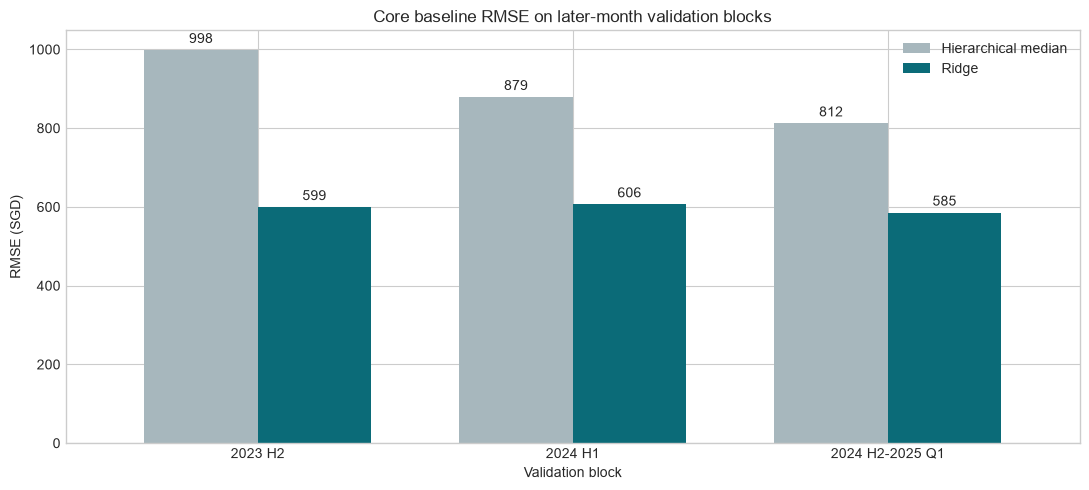

In [7]:
selected_parts = []
for variant in datasets:
    alpha = selected_alpha[variant]
    selected_parts.append(results[(results["variant"] == variant) & (results["model"] == "Hierarchical median")])
    selected_parts.append(results[(results["variant"] == variant) & (results["model"] == "Ridge") & (results["alpha"] == alpha)])
selected_results = pd.concat(selected_parts).sort_values(["variant", "fold", "model"])
display(selected_results)

mean_comparison = selected_results.groupby(["variant", "model"])[["RMSE", "MAE", "R2"]].mean()
display(mean_comparison)

core_mean = mean_comparison.loc["core"]
reference_rmse = core_mean.loc["Hierarchical median", "RMSE"]
ridge_rmse = core_mean.loc["Ridge", "RMSE"]
relative_gain = 100 * (reference_rmse - ridge_rmse) / reference_rmse
print(f"Core Ridge reduces mean RMSE by {relative_gain:.1f}% versus the hierarchical-median reference.")

core_plot = selected_results[selected_results["variant"].eq("core")].pivot(
    index="fold", columns="model", values="RMSE"
)
ax = core_plot[["Hierarchical median", "Ridge"]].plot(
    kind="bar", figsize=(11, 5), color=["#A7B7BD", "#0B6B78"], width=0.72
)
ax.set(title="Core baseline RMSE on later-month validation blocks", xlabel="Validation block", ylabel="RMSE (SGD)")
ax.tick_params(axis="x", rotation=0)
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)
ax.legend(title="")
plt.tight_layout()
plt.show()


## Core-only baseline result

- The core result above averages three later-month validation blocks rather than a random split.
- RMSE is the primary metric because the competition penalizes large rental errors more strongly.
- MAE shows the typical absolute SGD error and is less sensitive to a few large misses.
- $R^2$ shows how much variation the linear baseline explains within each future block.
- The hierarchical median provides a simple historical reference using only town and flat type.

The auxiliary variant is still trained and predicted, but the presentation reports core-only baseline metrics so the benchmark remains easy to interpret.


## Core error diagnostics on the latest future block

The latest core validation fold is the closest available proxy for the unseen future. Residual is `actual - predicted`; a positive mean residual means the model underpredicts. The plots check calibration and month-level drift beyond the aggregate RMSE.


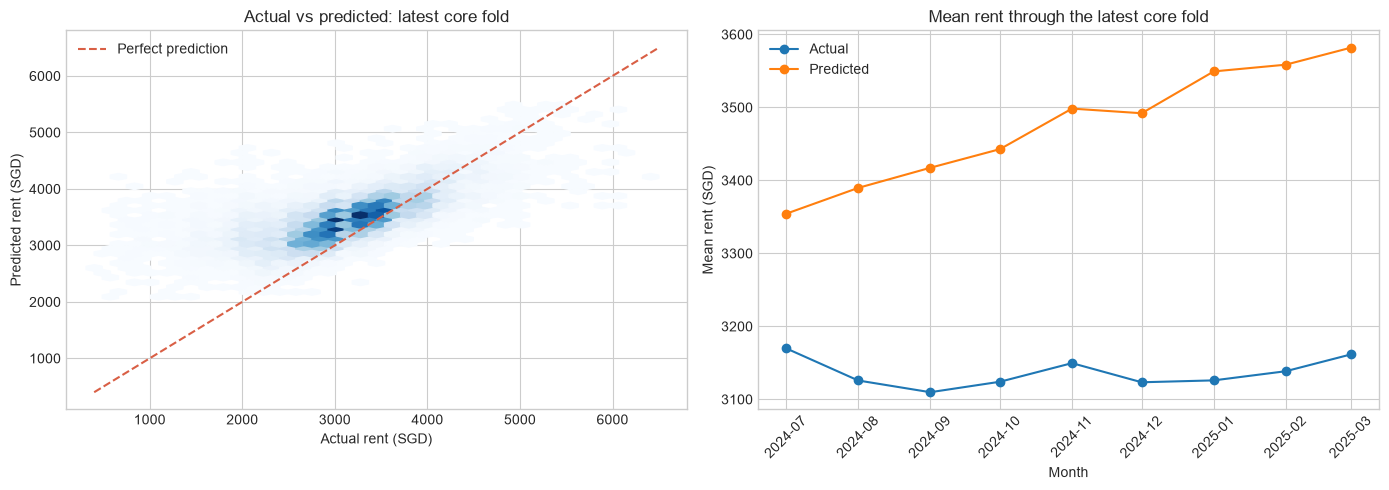

Mean residual (actual - predicted): SGD -338.7


In [8]:
variant = "core"
train = datasets[variant]["train"]
latest = SPLITS[-1]
latest_mask = train["RENT_DATE"].between(
    pd.Timestamp(latest["start"]), pd.Timestamp(latest["end"]), inclusive="left"
)
latest_diagnostics = train.loc[latest_mask, ["RENT_DATE", "TOWN", "FLAT_TYPE", TARGET]].copy()
latest_diagnostics["prediction"] = fold_predictions[(variant, latest["fold"], selected_alpha[variant])]
latest_diagnostics["residual"] = latest_diagnostics[TARGET] - latest_diagnostics["prediction"]
latest_diagnostics["absolute_error"] = latest_diagnostics["residual"].abs()
latest_diagnostics["squared_error"] = latest_diagnostics["residual"].pow(2)

monthly_diagnostics = latest_diagnostics.groupby("RENT_DATE").agg(
    actual=(TARGET, "mean"), prediction=("prediction", "mean")
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hexbin(
    latest_diagnostics[TARGET], latest_diagnostics["prediction"],
    gridsize=35, mincnt=1, cmap="Blues"
)
limits = [latest_diagnostics[TARGET].min(), latest_diagnostics[TARGET].max()]
axes[0].plot(limits, limits, "--", color="#D95F45", label="Perfect prediction")
axes[0].set(title="Actual vs predicted: latest core fold", xlabel="Actual rent (SGD)", ylabel="Predicted rent (SGD)")
axes[0].legend()

axes[1].plot(monthly_diagnostics.index, monthly_diagnostics["actual"], marker="o", label="Actual")
axes[1].plot(monthly_diagnostics.index, monthly_diagnostics["prediction"], marker="o", label="Predicted")
axes[1].set(title="Mean rent through the latest core fold", xlabel="Month", ylabel="Mean rent (SGD)")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"Mean residual (actual - predicted): SGD {latest_diagnostics['residual'].mean():,.1f}")


In [9]:
def subgroup_metrics(frame, group_column):
    return (
        frame.groupby(group_column)
        .agg(
            rows=(TARGET, "size"),
            MAE=("absolute_error", "mean"),
            RMSE=("squared_error", lambda values: np.sqrt(values.mean())),
            bias=("residual", "mean"),
        )
        .sort_values("RMSE", ascending=False)
    )

print("Latest-fold error by flat type:")
display(subgroup_metrics(latest_diagnostics, "FLAT_TYPE"))
print("Towns with the highest latest-fold RMSE (minimum 200 validation rows):")
town_errors = subgroup_metrics(latest_diagnostics, "TOWN")
display(town_errors.query("rows >= 200").head(10))

Latest-fold error by flat type:


,rows,MAE,RMSE,bias
FLAT_TYPE,,,,
2-room,699,496.734,644.949,-474.948
3-room,8347,469.543,613.784,-427.457
executive,1307,424.559,589.805,-158.385
1-room,10,489.562,581.588,-489.562
4-room,9383,418.319,572.290,-321.080
5-room,5877,404.877,554.246,-264.486


Towns with the highest latest-fold RMSE (minimum 200 validation rows):


,rows,MAE,RMSE,bias
TOWN,,,,
jurong west,1782,453.089,638.145,-251.788
kallang/whampoa,983,470.040,636.959,-327.091
bukit merah,1470,451.633,622.675,-313.905
queenstown,1005,463.130,620.751,-340.871
woodlands,1296,443.311,604.763,-369.313
yishun,1325,445.532,601.711,-392.297
geylang,743,447.538,598.837,-342.554
toa payoh,991,437.539,596.132,-322.708
ang mo kio,1395,441.321,593.882,-392.652


## Interpreting the fitted core baseline

The following refit uses only data before the latest validation block. Numeric coefficients correspond to a one-standard-deviation change. Categorical coefficients are regularized one-hot adjustments. Correlated address fields can share weight, so coefficients are descriptive rather than causal.


In [10]:
variant = "core"
train = datasets[variant]["train"]
contract = contracts[variant]
latest_start = pd.Timestamp(SPLITS[-1]["start"])
interpretation_train = train[train["RENT_DATE"] < latest_start]
interpretation_preprocessor = make_preprocessor(contract)
X_interpretation = interpretation_preprocessor.fit_transform(interpretation_train[contract["features"]])
interpretation_model = Ridge(
    alpha=selected_alpha[variant], solver="lsqr", max_iter=10_000, tol=1e-4
).fit(X_interpretation, interpretation_train[TARGET])

coefficient_table = pd.DataFrame({
    "feature": interpretation_preprocessor.get_feature_names_out(),
    "coefficient_sgd": interpretation_model.coef_,
})
display(coefficient_table.nsmallest(12, "coefficient_sgd"))
display(coefficient_table.nlargest(12, "coefficient_sgd"))


,feature,coefficient_sgd
6037,categorical__PROPERTY_KEY_queenstown|27|ghim m...,-420.418
36,categorical__TOWN_woodlands,-325.010
3964,categorical__PROPERTY_KEY_bukit timah|5|toh yi...,-316.267
3774,categorical__PROPERTY_KEY_bukit merah|69|redhi...,-302.771
6208,categorical__PROPERTY_KEY_sembawang|418|canber...,-300.395
31,categorical__TOWN_sembawang,-297.268
5523,categorical__PROPERTY_KEY_kallang/whampoa|8|sa...,-296.412
20,categorical__TOWN_choa chu kang,-289.922
7584,categorical__PROPERTY_KEY_woodlands|753|woodla...,-289.864
32,categorical__TOWN_sengkang,-287.355


,feature,coefficient_sgd
16,categorical__TOWN_bukit merah,465.075
2391,categorical__STREET_lim liak street,464.122
8039,categorical__TOWN_STREET_bukit merah|lim liak ...,464.122
2666,categorical__FLAT_MODEL_adjoined flat,397.040
19,categorical__TOWN_central,395.611
2381,categorical__STREET_kim cheng street,365.488
8035,categorical__TOWN_STREET_bukit merah|kim cheng...,365.488
30,categorical__TOWN_queenstown,364.559
2570,categorical__STREET_tiong bahru road,344.783
8053,categorical__TOWN_STREET_bukit merah|tiong bah...,344.783


## How to improve beyond the baseline

- Test nonlinear models on the same chronological folds.
- Add interactions between time, town, flat type, and floor area.
- Replace the conservative MRT proxy with month-specific station opening dates.
- Add schools, malls, COE, or stock data one feature group at a time.
- Retain a feature group only when later-period RMSE improves consistently.


## Fit both variants and write predictions

Each selected pipeline is refitted on all labelled rows for its variant. The test predictions are mapped to the sample submission by `ROW_ID`, preserving all 50,000 IDs even when test feature vectors repeat.


In [11]:
sample = pd.read_csv(SAMPLE_SUBMISSION_PATH)
assert sample.columns.tolist() == ["Id", "Predicted"]
assert sample["Id"].is_unique
SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)

prediction_summaries = []
submission_paths = {}
for variant, dataset in datasets.items():
    train, test = dataset["train"], dataset["test"]
    contract = contracts[variant]
    pipeline = Pipeline([
        ("preprocessor", make_preprocessor(contract)),
        ("ridge", Ridge(alpha=selected_alpha[variant], solver="lsqr", max_iter=10_000, tol=1e-4)),
    ])
    pipeline.fit(train[contract["features"]], train[TARGET])
    predictions = pipeline.predict(test[contract["features"]])
    prediction_by_id = pd.Series(predictions, index=test[ROW_ID], name="Predicted")
    submission = sample[["Id"]].copy()
    submission["Predicted"] = submission["Id"].map(prediction_by_id)
    assert submission["Predicted"].notna().all() and np.isfinite(submission["Predicted"]).all()
    filename = "ridge_baseline_core.csv" if variant == "core" else "ridge_baseline_hdb_mrt.csv"
    output_path = SUBMISSION_DIR / filename
    submission.to_csv(output_path, index=False)
    submission_paths[variant] = output_path
    prediction_summaries.append({
        "variant": variant,
        "alpha": selected_alpha[variant],
        "rows": len(submission),
        "prediction_min": submission["Predicted"].min(),
        "prediction_mean": submission["Predicted"].mean(),
        "prediction_max": submission["Predicted"].max(),
        "file": str(output_path.relative_to(ROOT)),
    })

display(pd.DataFrame(prediction_summaries).set_index("variant"))
print("Saved predictions:")
for variant, output_path in submission_paths.items():
    print(f"- {variant}: {output_path.relative_to(ROOT)}")


,alpha,rows,prediction_min,prediction_mean,prediction_max,file
variant,,,,,,
core,10.000,50000,"2,005.335","3,630.277","5,789.287",submissions/ridge_baseline_core.csv
core+hdb_mrt,10.000,50000,"1,960.349","3,638.739","5,749.913",submissions/ridge_baseline_hdb_mrt.csv


Saved predictions:
- core: submissions/ridge_baseline_core.csv
- core+hdb_mrt: submissions/ridge_baseline_hdb_mrt.csv
